# Organograma

## Importação e Tratamento

In [1]:
import pandas as pd 
df = pd.read_csv('../radarrj_ato_limpo.csv', sep='|')
print(len(df))

90450


In [2]:
df['id'] = df['id'].astype(int)
df['dataPubli'] = pd.to_datetime(df['dataPubli'])
df = df.sort_values(by='dataPubli', ascending=True)
df = df.reset_index(drop=True)
df.tail(1)

,id,idExPaAux,createdAt,dataPubli,parte,secao,subsecao,norma,texto
90449,2745582,3603076,2026-07-01 12:14:38,2026-07-01,Parte II (Poder Legislativo),Expediente Despachado pelo Presidente,NaN,II - Ofícios,PROJETO DE LEI Nº 7929/2026 DECLARA DE UTIL...


In [3]:
df_diarios = pd.read_csv('../materias_.csv',sep = '|')

df_diarios

,id,dataPubli,secao,texto
0,1009438,NaN,SECRETARIA DE ESTADO DE ADMINISTRAÇÃO PENITENC...,ATOS DO SECRETÁRIO RESOLUÇÃO SEAP Nº 363 DE...
1,1058914,NaN,SECRETARIA DE ESTADO DE EDUCAÇÃO - SEEDUC,DECRETO Nº 42.733 DE 06 DE DEZEMBRO DE 2010 ...
2,1078413,NaN,SECRETARIA DE ESTADO DE DESENVOLVIMENTO REGION...,DECRETO Nº 42.817 DE 26 DE JANEIRO DE 2011 ...
3,1093266,NaN,SECRETARIA DE ESTADO DE SAÚDE E DEFESA CIVIL,DECRETO N º 42.862 DE 23 DE FEVEREIRO DE 2011 ...
4,1124082,NaN,SECRETARIA DE ESTADO DE SEGURANÇA - SESEG,DECRETO Nº 42.940 DE 29 DE ABRIL DE 2011 AL...
...,...,...,...,...
185,806494,NaN,SECRETARIA DE ESTADO DA CASA CIVIL,DECRETO Nº 41.954 DE 17 DE JULHO DE 2009 AL...
186,828894,NaN,SECRETARIA DE ESTADO DE SAÚDE E DEFESA CIVIL 1...,ANEXO II A QUE SE REFERE O DECRETO Nº 42.009 ...
187,830707,NaN,SECRETARIA DE ESTADO DE EDUCAÇÃO - SEEDUC,DECRETO Nº 42.013 DE 28 DE AGOSTO DE 2009 D...
188,887811,NaN,Secretaria de Estado de Fazenda,DECRETO Nº 42.184 DE 11 DE DEZEMBRO DE 2009 ...


## Normas

In [4]:
set_normas = set(df['norma'].dropna().unique())
print(set_normas)

{'I - Resolução Conjunta', 'I - Decreto Pessoal', 'II - Resoluções', 'IV - Editais: Licitações', 'II - Moções', 'I - Lei', 'IB - Ato Executivo', 'II - Despachos do Diretor-Geral', 'V - Impacto Ambiental', 'V - Aviso de Leilão Extrajudicial', 'V - Demonstrações Financeiras (Balanços)', 'II - Projeto de Decreto Legislativo', 'I - Lei Complementar', 'DOCG - Quadro Geral de Precos', 'DOCG - Termos de Reconhecimento de Dívidas', 'I - Extrato de Termo', 'II - Mensagem', 'II - Atos do Presidente', 'IB - Pauta Especial', 'II - Atos da Mesa Diretora', 'IB - Despacho', 'V - Avisos, Editais e Termos', 'IB - Edital de Comunicação (Plenário)', 'DOCG - Ato', 'I - Veto Parcial', 'DPGE - Despacho', 'I - Extrato de Termo Aditivo', 'I - Decreto Normativo', 'I - Pauta', 'IB - Errata', 'I - Ordem de Serviço', 'IB - Extrato de Termo de Contrato', 'II - Projeto de Lei', 'I - Ato Pessoal', 'I - Edital', 'I - Aviso', 'IB - Portaria', 'I - Deliberação', 'IDN - MATÉRIA', 'II - Atos do Diretor-Geral', 'DOCG - Po

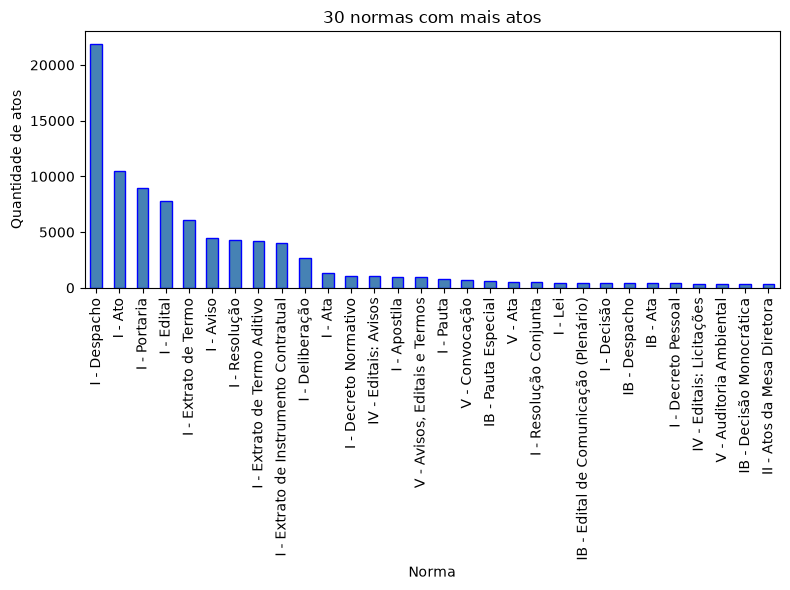

In [5]:
import matplotlib.pyplot as plt

contagem_normas = df['norma'].value_counts(dropna=True)
contagem_normas_top = contagem_normas.head(30)

ax = contagem_normas_top.plot(
    kind='bar',
    figsize=(8, 6),
    color='steelblue',
    edgecolor='blue',
    linewidth=1
)
ax.set_title('30 normas com mais atos')
ax.set_xlabel('Norma')
ax.set_ylabel('Quantidade de atos')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()

## Visualização Secretarias

In [10]:
import re
import unicodedata
def _chave_secao(nome):
    """Chave para agrupar secretarias iguais que diferem só por
    caixa alta/baixa ou por uma sigla no final (' - XXX' ou '(XXX)')."""
    s = str(nome)
    # separa quando há mais de uma secretaria no mesmo campo
    partes = re.split(r"\s*;\s*", s.strip())
    chaves = []
    for p in partes:
        # remove sigla no final: " - SEEDUC", " – GSI/RJ", " (SETRANS)"
        p = re.sub(r"\s*[-–—(]\s*[A-Za-zÀ-ÿ][A-Za-zÀ-ÿ/.\s-]*\)?\s*$", "", p)
        # sem acento, maiúsculas, espaços normalizados
        p = unicodedata.normalize("NFKD", p)
        p = "".join(c for c in p if not unicodedata.combining(c))
        p = re.sub(r"\s+", " ", p).strip().upper()
        chaves.append(p)
    return "; ".join(dict.fromkeys(chaves))


df_diarios["_chave"] = df_diarios["secao"].map(_chave_secao)

# nome de exibição = variação mais frequente de cada chave
representante = (
    df_diarios.groupby("_chave")["secao"]
    .agg(lambda s: s.value_counts().index[0])
)
df_diarios["secao"] = df_diarios["_chave"].map(representante)
df_diarios.drop(columns="_chave", inplace=True)

print(f"Secretarias únicas após limpeza: {df_diarios['secao'].nunique()}")


IndexError: index 0 is out of bounds for axis 0 with size 0

In [11]:
df_diarios['secao'].unique()

<StringArray>
[                                                                                                                                                 'SECRETARIA DE ESTADO DE ADMINISTRAÇÃO PENITENCIÁRIA - SEAP',
                                                                                                                                                                   'SECRETARIA DE ESTADO DE EDUCAÇÃO - SEEDUC',
                                                                                                                            'SECRETARIA DE ESTADO DE DESENVOLVIMENTO REGIONAL, ABASTECIMENTO E PESCA - SEDRAP',
                                                                                                                                                                'SECRETARIA DE ESTADO DE SAÚDE E DEFESA CIVIL',
                                                                                                                                                          

C:\Users\daniel.pereira\AppData\Local\Temp\ipykernel_27916\129764696.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


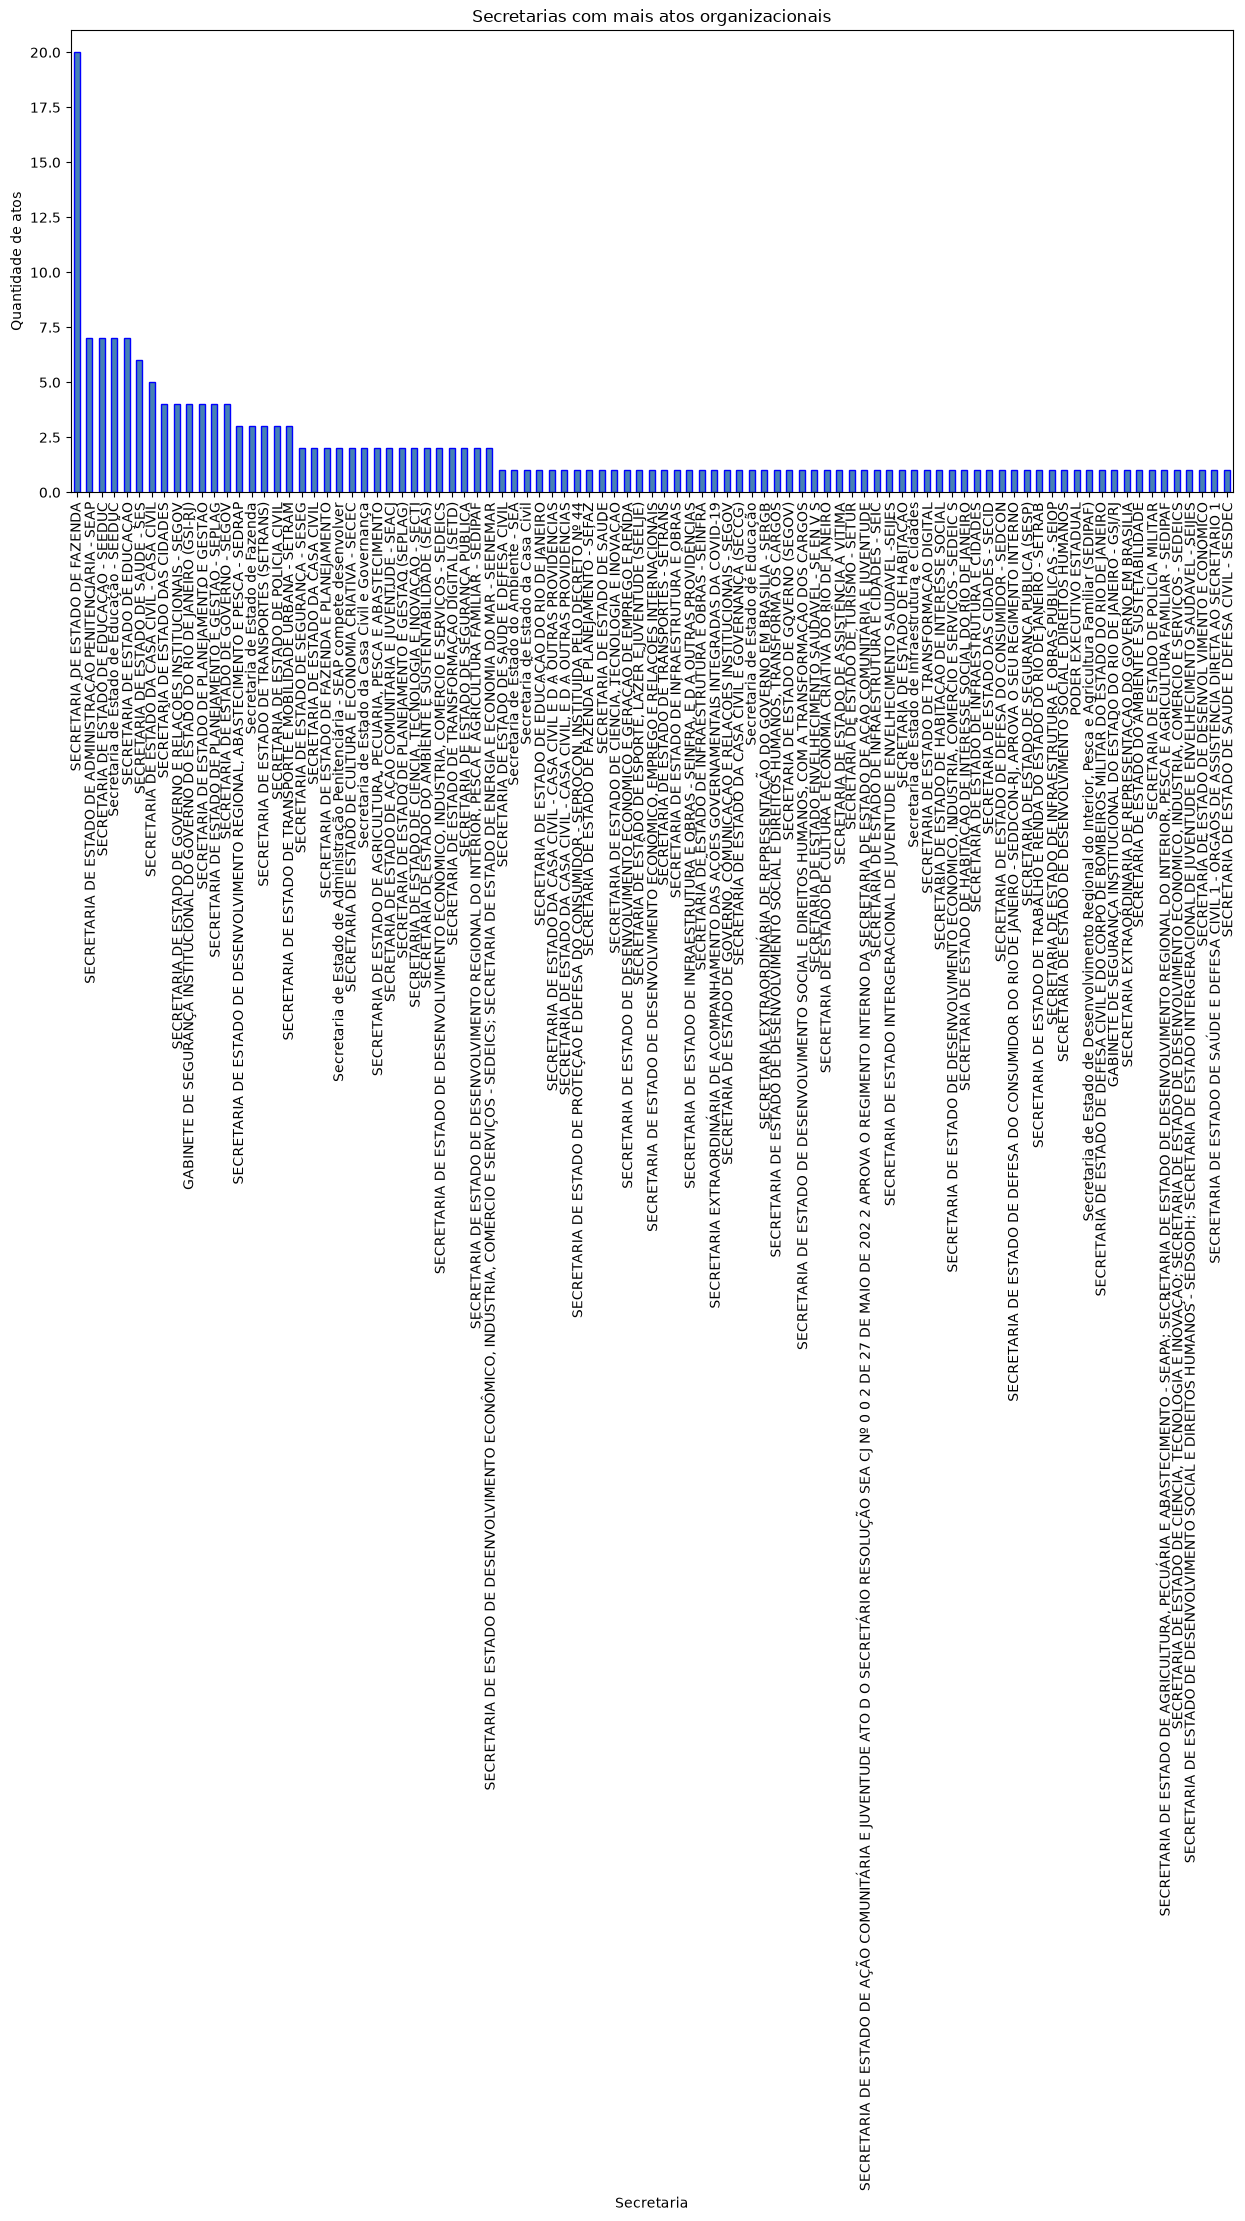

In [13]:
import matplotlib.pyplot as plt
contagem_secretarias = df_diarios['secao'].value_counts(dropna=True)
ax = contagem_secretarias.plot(
    kind='bar',
    figsize=(15, 6),
    color='steelblue',
    edgecolor='blue',
    linewidth=1
)
ax.set_title('Secretarias com mais atos organizacionais')
ax.set_xlabel('Secretaria')
ax.set_ylabel('Quantidade de atos')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()

## Busca por atos com Organização da Secretaria

### Busca

In [14]:
import re
import unicodedata


def remover_acentos(texto):
    texto_normalizado = unicodedata.normalize("NFKD", texto)
    return "".join(
        caractere
        for caractere in texto_normalizado
        if not unicodedata.combining(caractere)
    )


# Exige pontuação depois do "1": casa "1.", "1-", "1 -", "1)", "1 )".
# NÃO casa "1 GABINETE" (sem pontuação).
padrao_gabsec = r"(?<!\d)1\s*[\.\)\-–]\s*GABINETE\s+DO\s+SECRETARIO\b"
padrao_regimento = r"\bREGIMENTO\s+INTERNO\s+DA\s+SECRETARIA\b"

texto_normalizado = df["texto"].fillna("").map(remover_acentos)

df["gabsec"] = texto_normalizado.str.contains(
    padrao_gabsec,
    case=False,
    regex=True,
    na=False,
)
df["regimento"] = texto_normalizado.str.contains(
    padrao_regimento,
    case=False,
    regex=True,
    na=False,
)

contagem_gabsec = df.loc[df["gabsec"], "norma"].value_counts(dropna=True)
contagem_regimento = df.loc[df["regimento"], "norma"].value_counts(dropna=True)

print(f"Atos encontrados: {df['gabsec'].sum()}")
print(f"Atos com regimento: {df['regimento'].sum()}")

Atos encontrados: 16
Atos com regimento: 30


### Função extração organização

In [15]:
import json
import re
import unicodedata


# ============================================================ util de texto
def normalizar_texto(texto):
    if texto is None:
        return ""
    texto = str(texto)
    texto = texto.replace("&nbsp;", " ").replace("\xa0", " ")
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = texto.replace("\r\n", "\n").replace("\r", "\n")
    return texto


def indice_para_tupla(indice):
    indice = str(indice).strip()
    if not re.fullmatch(r"\d+(?:\.\d+)*", indice):
        return None
    return tuple(int(p) for p in indice.split("."))


_ROMANO_VAL = {
    "i": 1, "ii": 2, "iii": 3, "iv": 4, "v": 5, "vi": 6, "vii": 7, "viii": 8,
    "ix": 9, "x": 10, "xi": 11, "xii": 12, "xiii": 13, "xiv": 14, "xv": 15,
    "xvi": 16, "xvii": 17, "xviii": 18, "xix": 19, "xx": 20,
}


def _romano_para_int(r):
    return _ROMANO_VAL.get(re.sub(r"\s+", "", str(r).lower()))


_MINUSC = {"de", "da", "do", "das", "dos", "e", "a", "o", "as", "os", "em", "para", "com"}


def _titlecase_pt(txt):
    """Title-case mantendo conectivos (de, da, do, e...) em minúsculo."""
    if not txt.isupper():
        return txt
    return " ".join(
        p if (p.lower() in _MINUSC and i) else p.capitalize()
        for i, p in enumerate(txt.split())
    )


def extrair_sigla_e_nome(nome):
    """Separa '... - SIGLA' / '... (SIGLA)' do nome. Só considera sigla se for
    curta e em CAIXA ALTA (evita 'E-Social', '(Fundacao CEPERJ)')."""
    nome = re.sub(r"\s+", " ", str(nome)).strip()
    nome = re.sub(r"\s*\(\.*\)\s*$", "", nome).strip()          # '(...)' placeholder
    if not nome:
        return "", None
    m = re.search(r"^(.*?)(?:\s*\(([^()]{2,40})\)|\s*[-–]\s*([A-Z][A-Z0-9./\-]{1,18}))\s*$", nome)
    if m:
        base = (m.group(1) or "").strip(" -–:;,.")
        sigla = (m.group(2) or m.group(3) or "").strip()
        if re.fullmatch(r"[A-Z][A-Z0-9./\-]{1,18}", sigla) and base:
            return base, sigla
    return nome.strip(" -–:;,.()"), None


# ================================================ nome da secretaria (fallback)
def _limpar_nome_secretaria(nome):
    nome = re.sub(r"\s+", " ", str(nome)).strip()
    # corta em cabeçalho de seção romana / de estrutura que tenha grudado no nome
    nome = re.split(
        r"\s+(?:I{1,3}|IV|VI{0,3}|IX|XI{0,3}|X|V)\s*[-–]\s+[A-ZÀ-Ý]"
        r"|\bESTRUTURA\s+(?:BASICA|ORGANIZACIONAL)"
        r"|\bORGAOS?\s+DE\s+ASSISTENCIA"
        r"|\bA\s+QUE\s+SE\s+REFERE",
        nome, maxsplit=1, flags=re.IGNORECASE,
    )[0]
    nome = re.sub(
        r"^(?:[IVXLC]+\s*[-.–]\s*)?(?:A|O|AS|OS|DA|DO|DE)\s+(?=SECRETARI|GABINETE)",
        "", nome, flags=re.IGNORECASE,
    )
    nome = re.sub(r"\s+[A-Za-z]\s*$", "", nome)      # letra solta no fim ("... DIGITAL A")
    nome = nome.strip(" -–:;,.()")
    return nome.upper()


def _secretaria_pelo_texto(texto_norm, offset_gab):
    antes = re.sub(r"\s+", " ", texto_norm[:offset_gab]).strip()
    if not antes:
        return None

    # (B) cabeçalho SECRETARIA/GABINETE ... imediatamente antes do gabinete
    mb = re.search(
        r"(SECRETARI[AO]|GABINETE)\s+"
        r"((?:DE|DO|DA|EXTRAORDINARI[AO])(?:\s+[A-Z0-9&/().,\-]+)+?)"
        r"\s*[:;.\-]*\s*$",
        antes,
    )
    if mb:
        pref = "SECRETARIA" if mb.group(1).upper().startswith("SECRETARI") else "GABINETE"
        nome = _limpar_nome_secretaria(f"{pref} {mb.group(2)}")
        if len(nome) >= 10:
            return nome

    # (A) "estrutura (organizacional|basica) d_ <nome>"
    ma = list(re.finditer(
        r"estrutura\s+(?:organizacional|basica)\s+d[aeo]\s+(.+?)\s*"
        r"(?:[,.:(]|\bna\s+forma\b|\bconforme\b|\bcompreende\b|\bcompete\b"
        r"|\bsera\b|\btera\b|\bpassa\w*|\bfica\w*\b|\be\s+d[ao]s?\b"
        r"|\s(?:I{1,3}|IV|VI{0,3}|X|V)\s*[-–]\s|$)",
        antes, flags=re.IGNORECASE,
    ))
    if ma:
        nome = _limpar_nome_secretaria(ma[-1].group(1))
        if len(nome) >= 10 and re.search(r"SECRETARI|GABINETE", nome):
            return nome

    # (C) última menção "Secretari_ de ..."
    mc = list(re.finditer(
        r"(SECRETARI[AO]\s+(?:DE|DO|DA|EXTRAORDINARI[AO])\s+[A-Za-z0-9&/().,\-\s]+?)"
        r"(?:[,.:(]|\bna\s+forma\b|\bconforme\b|\bsera\b|\btera\b|\bque\b|\btem\b"
        r"|\s(?:I{1,3}|IV|VI{0,3}|X|V)\s*[-–]\s|$)",
        antes, flags=re.IGNORECASE,
    ))
    if mc:
        nome = _limpar_nome_secretaria(mc[-1].group(1))
        if len(nome) >= 10 and "SECRETARI" in nome:
            return nome
    return None


def _resolver_secretaria(texto_norm, offset_gab, secao):
    if secao is not None:
        s = str(secao).strip()
        if re.match(r"^(secretaria|gabinete)\b", s, flags=re.IGNORECASE):
            # 'secao' já vem só com o(s) nome(s); corta um eventual "I - ORGAOS..."
            return _limpar_nome_secretaria(s)
    if offset_gab is not None:
        return _secretaria_pelo_texto(texto_norm, offset_gab)
    return None


# =================================================== deteccao do "1. Gabinete"
# AGORA exige pontuação depois do "1" (não casa "1 Gabinete do Secretario")
PADRAO_GABINETE = re.compile(
    r"(?<!\d)1\s*[.)\-–]\s*gabinete\s+d[oe]s?\s*secretari[oa]",
    flags=re.IGNORECASE,
)


def procurar_inicio_gabinete(texto):
    texto = normalizar_texto(texto)
    m = PADRAO_GABINETE.search(texto)
    return (m.start() if m else None)


# ================================================ seções de nível 1 (listas)
_CATS = [
    ("Entes Vinculados", re.compile(
        r"(?:entes?|entidades?)\s+(?:e\s+(?:entes?\s+)?)?vinculad"
        r"|(?:entes?|entidades?)\s+supervisionad"
        r"|\bsupervisionad[oa]s?\b"
        r"|^\W*orgaos?\s+e\s+entidades?\s+vinculad"
        r"|^\W*orgaos?\s+vinculad\w*\s*:?\s*$"
        r"|^\W*orgao\s+vinculad", re.I)),
    ("Orgaos Colegiados", re.compile(r"orgaos?\s+colegiad|^\W*colegiad", re.I)),
    ("Comissoes", re.compile(r"^\W*comiss[oõa]", re.I)),
    ("Fundos", re.compile(r"\bfundos?\b|administracao\s+de\s+fundos", re.I)),
]
_CAT_NOMES = [c for c, _ in _CATS]

# títulos de seção romana que, apesar da palavra "vinculad", SÃO parte da árvore
_RX_SECAO_ARVORE = re.compile(
    r"especific|singular|subordinad|assistencia\s+direta|ao\s+secretario"
    r"|a\s+chefia|ao\s+gabinete|de\s+planejamento|de\s+coordenacao"
    r"|de\s+correicao|de\s+inteligencia|de\s+assessoramento|de\s+representacao"
    r"|de\s+atividades", re.I,
)


def _classificar_secao(titulo):
    if _RX_SECAO_ARVORE.search(titulo):
        return None
    for nome, rx in _CATS:
        if rx.search(titulo):
            return nome
    return None


# começo provável do nome de um ente/órgão numa lista corrida
_ORG_INI = (
    r"Conselh\w+|Comit[eê]\w*|Comiss[aã]o|C[aâ]mara|Junta|F[oó]rum|Sistema"
    r"|Fund\w+|Companhia|Institut\w+|Departament\w+|Empresa|Ag[eê]ncia|Autarquia"
    r"|Superintend\w+|Centro|Programa|Coordenad\w+|Secretaria|Nucleo|Servico"
    r"|Escritorio|Diretoria|Assessoria|Loteria|Imprensa|Radio|Universidade"
)
_RX_ORG_INI = re.compile(r"(?<![A-Za-zÀ-ÿ])(?:%s)\b" % _ORG_INI, re.I)
_RX_ORG_SPLIT = re.compile(r"(?<=[a-zç0-9)\]])\s+(?=(?:%s)\b)" % _ORG_INI, re.I)
# não separar "Fundacao Instituto ...", "Conselho Gestor do Fundo ..." etc:
# palavras que formam nome composto com o próximo termo-início
_RX_NAO_SEPARAR = re.compile(
    r"\b(?:Fundacao|Fundo|Instituto|Conselho|Companhia|Departamento|Ag[eê]ncia"
    r"|Centro|C[aâ]mara|Superintend\w+|Coordenad\w+|Comiss[aã]o|Comit[eê]"
    r"|Sistema|Servico|Nucleo|Escritorio|Diretoria|Assessoria|Junta|Secretaria"
    r"|Universidade|Autarquia|de|d[oa]s?|e|para|com)\s*$", re.I,
)
_RX_CORTA_LISTA = re.compile(
    r"\bANEXO\s+[IVX0-9]|\bId:\s*\d|\bCAP[IÍ]TULO\b|\bT[IÍ]TULO\b|\bSUBSE[CÇ][AÃ]O"
    r"|COMPET[EÊ]NCIAS?\s+E?\s*ATRIBUI|\bArt\.?\s*\d"
    r"|\b(?:Rio de Janeiro|Brasilia),?\s+\d?\d\s+de\s+\w+\s+de\s+\d{4}"
    r"|(?:^|\s{2,})(?:I{1,3}|IV|VI{0,3}|IX|XI{0,3}|X|V)\s*[-–]\s+[A-ZÀ-Ý]{2,}\b",
    re.I,
)


def _parse_lista_entes(corpo):
    corpo = _RX_CORTA_LISTA.split(corpo, maxsplit=1)[0]
    corpo = re.sub(r"^\s*(?:e\s*/?\s*ou\s+|/\s*)?supervisionad[oa]s?\b\s*:?", "", corpo, flags=re.I)
    corpo = re.sub(r"(?<![A-Za-zÀ-ÿ])[a-z]\)\s*", "  ", corpo)   # marcadores a) b)
    corpo = corpo.replace("§", "  ").replace("·", "  ").replace("•", "  ")
    corpo = re.sub(r"[ \t]{2,}|\n", "\n", corpo)                  # blocos -> linhas
    itens, vistos = [], set()

    for pedaco in corpo.split("\n"):
        pedaco = pedaco.strip(" ;.,-–•")
        if len(pedaco) < 4:
            continue
        # separa "Conselho X   Conselho Y" (um ente ao lado do outro), sem
        # quebrar nomes compostos ("Fundacao Instituto ...")
        marcado = []
        pos = 0
        for m in _RX_ORG_SPLIT.finditer(pedaco):
            if not _RX_NAO_SEPARAR.search(pedaco[max(0, m.start() - 25):m.start()]):
                marcado.append(pedaco[pos:m.start()])
                pos = m.end()
        marcado.append(pedaco[pos:])
        subs = []
        for chunk in marcado:
            subs += re.split(
                r"(?<=[a-z])(?=[A-Z][a-zç])"        # "...FIAFundacao"
                r"|(?<=[A-Z]{2})(?=[A-Z][a-zç])"    # "...INEAFundo"
                r"|\s*;\s*",
                chunk,
            )
        for s in subs:
            s = re.sub(r"^\s*\d+(?:\.\d+)*\s*[.)\-–]?\s*", "", s)   # tira "1.1 "
            s = re.sub(r"[;,]?\s+e$", "", s.strip(" ;.,-–"))        # tira "; e"
            if len(s) < 4 or not re.search(r"[A-Za-zÀ-ÿ]{3}", s):
                continue
            nome, sigla = extrair_sigla_e_nome(s)
            nome = re.sub(r"\s+", " ", nome).strip(" ;.,-–")
            if len(nome) < 4:
                continue
            chave = (nome.lower(), sigla)
            if chave not in vistos:
                vistos.add(chave)
                itens.append({"nome": nome, "sigla": sigla})
    return itens


# ================================================= corte do nome de entidade
_RX_CORTA_NOME = re.compile(
    r"\s+(?:I{1,3}|IV|VI{0,3}|IX|XI{0,3}|X|V)\s*[-–]\s+[A-ZÀ-Ý]"      # " II - Xxx"
    r"|(?<=\S)\s+(?:Cargo\s+em\s+Comiss[aã]o|Denomina[cç][aã]o|Quantitativo)\s+S[ií]mbolo"
    r"|(?<=\S)\s+S[ií]mbolo\s+(?:Qt\b|Quant|N[ºo°]|Refer)"
    r"|(?<=\S)\s+(?:CAP[IÍ]TULO|T[IÍ]TULO|SE[CÇ][AÃ]O|SUBSE[CÇ][AÃ]O|ANEXO"
    r"|PAR[AÁ]GRAFO|Paragrafo|Par[aá]grafo)\b"
    r"|\s+Art\.?\s*\d"
    r"|\bId:\s*\d"
    r"|\s*\.{4,}"                                                     # "........"
    r"|\s*§"
    r"|(?<=[a-zç])\s+[a-z]\)\s"                                       # " a) assessorar..."
    r"|(?<=\S)\s+Compete\b"
    r"|(?<=\S)\s+P\s*ar[aá]grafo\b"
    r"|(?<=\S)\s+(?:ENTIDADES?|ENTES?)\s+(?:E\s+ENTES?\s+)?VINCULAD"
    r"|(?<=\S)\s+[OÓ]RG[AÃ]OS?\s+(?:E\s+ENTIDADES?\s+)?(?:VINCULAD|COLEGIAD)"
    r"|(?<=\S)\s+(?:D[AO]S?\s+)?COMPET[EÊ]NCIAS?\s+E?\s*ATRIBUI"
    r"|(?<=\S)\s+(?:Rio de Janeiro|Bras[ií]lia),?\s+\d?\d\s+de\s+\w+\s+de\s+\d{4}"
    r"|(?<=\S)\s+(?:CLAUDIO\s+CASTRO|SERGIO\s+CABRAL|LUIZ\s+FERNANDO|WILSON\s+WITZEL"
    r"|RICARDO\s+COUTO|Governador(?:\s+em\s+Exerc[ií]cio)?)\b",
    re.IGNORECASE,
)

# marca o fim da parte "estrutura" (começo do regimento / assinaturas / anexos)
_RX_FIM_ESTRUTURA = re.compile(
    r"\bCAP[IÍ]TULO\s+[IVX0-9]"
    r"|\bT[IÍ]TULO\s+[IVX0-9]"
    r"|\bANEXO\s+[IVX0-9]"
    r"|\bId:\s*\d"
    r"|\*?\s*Republicad\w*"
    r"|\bArt\.?\s*\d+\s*[.ºo°]?\s*[-–]"
    r"|\b(?:Rio de Janeiro|Bras[ií]lia),?\s+\d?\d\s+de\s+\w+\s+de\s+\d{4}"
    r"|\bDECRETA\s*:|\bResolve\s*:"
    r"|\b(?:D[AO]S?\s+)?COMPET[EÊ]NCIAS?\s+E?\s*ATRIBUI"
    r"|(?<![A-Za-z])(?:I{1,3}|IV|VI{0,3}|IX|XI{0,3}|X|V)\s*[-–]\s*(?:D[AO]S?\s+)?COMPET[EÊ]NCIA"
    r"|\bDISPOSI[CÇ][OÕ]ES\s+(?:FINAIS|GERAIS|TRANSITORIAS|PRELIMINARES)"
    r"|\bREGIMENTO\s+INTERNO\s+D"
    r"|\bAos?\s+[oó]rg[aã]os\s+integrantes\s+da\s+estrutura",
    re.I,
)


def _pre_normalizar_bloco(bloco):
    """Insere separador antes de índices/cabeçalhos romanos que vieram grudados
    no texto (artefato de extração do HTML): 'Gabinete1.2.' / 'GABSEC1.1.' /
    'InternaII -'. Preserva os '   ' (separadores de bloco) do diário."""
    bloco = re.sub(
        r"(?<=[A-Za-zçãõáéíóúâÀ-ÿ])(\d{1,3}(?:\.\d{1,3})+\.?)(?=[ .]?[A-ZÀ-Ý])",
        r"   \1 ", bloco,
    )
    # índice de 1 nível grudado numa sigla: "... - ASSGOV2. Subsecretaria"
    bloco = re.sub(
        r"(?<=[a-zçãõA-Z])([1-9]\.)(?=\s*[A-ZÀ-Ý][a-zà-ÿ])",
        r"   \1 ", bloco,
    )
    bloco = re.sub(
        r"(?<=[a-zçãõáéíóúâ])(I{2,3}|IV|VI{0,3}|IX|XI{0,3})(\s*[-–]\s+)(?=[A-ZÀ-Ý])",
        r"   \1\2", bloco,
    )
    return bloco


# cabeçalho de seção romana dentro do bloco (depois do gabinete)
_RX_ROMANO_HEADER = re.compile(
    r"(?<![A-Za-zÀ-ÿ0-9])"
    r"(I{1,3}|I\s*V|VI{0,3}|I\s*X|X\s*I{0,3}|X|V)"
    r"\s*[-–]\s*"
    r"([A-ZÀ-Ý][^\n]{2,90}?)"
    r"(?=\s{2,}|\s+\d+\s*[.)\-–]|\s*:|\s*$)",
)


def _dividir_secoes(bloco):
    """Divide o bloco em (romano_int, titulo, corpo). O trecho antes do 1º
    cabeçalho romano é a seção 1 (o Gabinete)."""
    headers = list(_RX_ROMANO_HEADER.finditer(bloco))
    secoes = []
    if not headers or headers[0].start() > 0:
        fim = headers[0].start() if headers else len(bloco)
        secoes.append((1, "", bloco[:fim]))
    for i, h in enumerate(headers):
        ini = h.end()
        fim = headers[i + 1].start() if i + 1 < len(headers) else len(bloco)
        secoes.append((_romano_para_int(h.group(1)), h.group(2).strip(), bloco[ini:fim]))
    return secoes


_RX_ENTIDADE = re.compile(
    r"(?<!\d)(\d+(?:\.\d+)*)\s*[.)\-–]?\s*(.*?)"
    r"(?=(?:\s+(?<!\d)\d+(?:\.\d+)*(?!\d)\s*[.)\-–\s])|$)",
    flags=re.S,
)


def _e_sucessor(prev, cur):
    """cur é um índice plausível depois de prev? (desce no mesmo ramo, ou é o
    próximo irmão/tio com incremento de 1 ou 2). Derruba números soltos do
    texto (quantidades de tabela, anos, nº de lei)."""
    if prev is None:
        return True
    if len(cur) >= len(prev) and cur[:len(prev)] == prev:
        return True
    for j in range(1, min(len(cur), len(prev)) + 1):
        if cur[:j - 1] == prev[:j - 1] and 1 <= cur[j - 1] - prev[j - 1] <= 2:
            return True
    return False


# rótulo de agrupamento que virou "nome" de um nó numerado
_RX_ROTULO_LIGA = re.compile(          # mantém como nó de ligação (nome curto)
    r"^[-–\s]*[OÓ]RG[AÃ]OS?\s+(?:E\s+ENTIDADES?\s+)?"
    r"(?:ESPECIFICO\w*(?:\s+SINGULAR\w*)?|DE\s+ATIVIDADES\s+\w+|DE\s+APOIO)", re.I,
)
_RX_ROTULO_DESCARTA = re.compile(      # descarta o nó inteiro
    r"^[-–\s]*(?:PROGRAMAS?\b|ATIVIDADES\s+AUXILIARES|COMISS[OÕ]ES\b"
    r"|[OÓ]RG[AÃ]OS?\s+(?:COLEGIAD|VINCULAD))", re.I,
)


def _limpar_nome_entidade(nome):
    nome = _RX_CORTA_NOME.split(nome, maxsplit=1)[0]
    # nome que atravessa um separador de bloco do diário (>=3 espaços) foi
    # "engolido": fica só com o primeiro bloco
    nome = re.split(r"\s{3,}", nome, maxsplit=1)[0]
    nome = re.sub(r"^[\s.\-–:;)]+", "", nome)
    nome = re.sub(r"[;,]?\s+e$", "", nome)                       # "...; e" / "..., e"
    nome = re.sub(r"[\s.\-–:;(]+$", "", nome)
    nome = re.sub(r"\s+", " ", nome)
    if _RX_ROTULO_DESCARTA.match(nome):
        return ""
    mliga = _RX_ROTULO_LIGA.match(nome)
    if mliga:
        return _titlecase_pt(mliga.group(0).strip(" -–"))
    return nome


_RX_TITULO_LIMPO = re.compile(
    r"\s+(?:VINCULAD\w*|SUBORDINAD\w*|SUPERVISIONAD\w*|AO\s+SECRETARIO|A\s+CHEFIA"
    r"|DO\s+SECRETARIO|E\s+IMEDIATA|DIRETA\s+E|D[EO]\s+ESTADO).*$", re.I,
)


def _titulo_secao_limpo(titulo):
    t = _RX_TITULO_LIMPO.sub("", titulo).strip(" -–:;,.")
    t = re.sub(r"\s+", " ", t)
    return _titlecase_pt(t)


def _parse_secao_arvore(corpo, romano_int, titulo, entidades, max_invalidas=6):
    """Extrai as entidades numeradas de uma seção. Se a numeração reinicia em
    '1' numa seção romana != 1, prefixa os índices com o número da seção.
    Se a seção tem filhos 'N.x' mas nenhum nó 'N', cria um a partir do título."""
    matches = list(_RX_ENTIDADE.finditer(corpo))
    prefixo = None
    ultimo = None
    invalidas = 0
    vistos_sec = set()

    for m in matches:
        indice = m.group(1)
        if re.match(r"0\d", indice):          # "01", "05" -> quantidade de tabela
            continue
        tup = indice_para_tupla(indice)
        if tup is None:
            continue

        # decide o prefixo na 1ª entidade válida da seção
        if prefixo is None and romano_int and romano_int != 1:
            if tup[0] != romano_int:          # numeração local -> reindexar
                prefixo = romano_int
            else:
                prefixo = 0                    # já está global
        if prefixo:
            tup = (prefixo,) + tup[1:] if len(tup) > 1 else (prefixo,)
            indice = ".".join(str(x) for x in tup)

        nome = _limpar_nome_entidade(m.group(2) or "")
        if not nome or not re.search(r"[A-Za-zÀ-ÿ]", nome):
            invalidas += 1
            if invalidas >= max_invalidas:
                break
            continue

        if ultimo is not None and not _e_sucessor(ultimo, tup):
            invalidas += 1
            if invalidas >= max_invalidas:
                break
            continue

        nome_limpo, sigla = extrair_sigla_e_nome(nome)
        if not nome_limpo:
            invalidas += 1
            continue

        if indice not in entidades:
            entidades[indice] = {
                "indice": indice, "nome": nome_limpo, "sigla": sigla, "filhos": [],
            }
            ultimo = tup
            invalidas = 0
            vistos_sec.add(tup[0])

    # seção romana com filhos "N.x" mas sem o nó "N" -> cria a partir do título
    for topo in vistos_sec:
        chave = str(topo)
        if chave not in entidades and titulo:
            rot = _titulo_secao_limpo(titulo)
            if rot and len(rot) >= 4:
                entidades[chave] = {
                    "indice": chave, "nome": rot, "sigla": None, "filhos": [],
                }


def _montar_arvore(entidades):
    pai_de = {}
    for indice in entidades:
        partes = indice.split(".")
        pai = None
        for k in range(len(partes) - 1, 0, -1):
            cand = ".".join(partes[:k])
            if cand in entidades:
                pai = cand
                break
        pai_de[indice] = pai
    ordem = sorted(entidades, key=lambda x: indice_para_tupla(x))
    for indice in ordem:
        if pai_de[indice] is not None:
            entidades[pai_de[indice]]["filhos"].append(entidades[indice])
    return [entidades[i] for i in ordem if pai_de[i] is None], ordem, pai_de


_RX_NOME_CATEGORIA = re.compile(
    r"^(?:entes?|entidades?|orgaos?)\s+(?:e\s+(?:entidades?\s+|entes?\s+)?)?"
    r"(?:vinculad|supervisionad)\w*"
    r"(?:\s*(?:e\s*/?\s*ou\s+|/\s*|e\s+)supervisionad\w*)?\s*[:/]?\s*"
    r"|^(?:orgaos?\s+)?colegiad\w*\s*:?\s*"
    r"|^comiss[oõ]es\b\s*:?\s*"
    r"|^(?:administracao\s+de\s+)?fundos\b\s*:?\s*", re.I,
)


def _categoria_do_nome(nome):
    m = _RX_NOME_CATEGORIA.match(nome or "")
    if not m:
        return None
    cat = _classificar_secao(nome)
    resto = (nome[m.end():]).strip(" -–:;,.") if cat else ""
    return (cat, resto) if cat else None


def _achatar(no):
    saida = [{"nome": no["nome"], "sigla": no["sigla"]}]
    for f in no["filhos"]:
        saida.extend(_achatar(f))
    return saida


def _podar_categorias(nos, listas):
    """Percorre a árvore (em qualquer nível): se um nó é 'Entes Vinculados' /
    'Orgaos Colegiados' / ... move os descendentes para a lista de nível 1
    e remove o nó da árvore."""
    mantidos = []
    for no in nos:
        achou = _categoria_do_nome(no["nome"])
        if achou:
            cat, resto = achou
            # nome do tipo "Entidades Vinculadas Fundacao Santa Cabrini"
            if resto and len(resto) >= 4:
                for it in _parse_lista_entes(resto):
                    if it not in listas[cat]:
                        listas[cat].append(it)
            for filho in no["filhos"]:
                for item in _achatar(filho):
                    if item not in listas[cat]:
                        listas[cat].append(item)
        else:
            no["filhos"] = _podar_categorias(no["filhos"], listas)
            mantidos.append(no)
    return mantidos


# ============================================================ função principal
def extrair_estrutura_organizacao(texto, secao=None):
    vazio_listas = {c: [] for c in _CAT_NOMES}
    texto_norm = normalizar_texto(texto)
    offset = procurar_inicio_gabinete(texto)

    secretaria = _resolver_secretaria(texto_norm, offset, secao)
    if offset is None:
        return {"raiz": None, "secretaria": secretaria, "arvore": [], **vazio_listas}

    # preserva os "   " (separadores de bloco do diário); só tira \n e tabs
    bloco = _pre_normalizar_bloco(texto_norm[offset:].replace("\n", "   ").replace("\t", " ").strip())

    # separa a "estrutura" da cauda (regimento / assinaturas / anexos)
    mfim = _RX_FIM_ESTRUTURA.search(bloco)
    bloco_estrut = bloco[:mfim.start()] if mfim else bloco

    listas = {c: [] for c in _CAT_NOMES}
    entidades = {}

    for romano_int, titulo, corpo in _dividir_secoes(bloco_estrut):
        cat = _classificar_secao(titulo) if titulo else None
        if cat:
            for item in _parse_lista_entes(corpo):
                if item not in listas[cat]:
                    listas[cat].append(item)
        else:
            _parse_secao_arvore(corpo, romano_int, titulo, entidades)

    if not entidades:
        return {"raiz": None, "secretaria": secretaria, "arvore": [], **listas}

    arvore, ordem, pai_de = _montar_arvore(entidades)

    raiz = ordem[0]
    if not re.search(
        r"gabinete\s+d[oe]s?\s*secretari[oa]|gabinete\s+secretaria",
        entidades[raiz]["nome"].lower(),
    ):
        return {"raiz": None, "secretaria": secretaria, "arvore": [], **listas}

    # nós (em qualquer nível) que na verdade são "Entes Vinculados /
    # Colegiados / ..." -> movem os descendentes para a lista de nível 1
    arvore_final = _podar_categorias(arvore, listas)

    return {"raiz": raiz, "secretaria": secretaria, "arvore": arvore_final, **listas}

### Chamada da função

#### Testes

In [ ]:
texto = """SECRETARIA DE ESTADO DE DESENVOLVIMENTO REGIONAL DO INTERIOR, AGRICULTURA FAMILIAR E PESCA

1. Gabinete do Secretário (GABSEC)
1.1 - Assessoria de Gabinete
1.1.1 - Assessoria de Comunicação
1.2 - Coordenação de Apoio
II - ÓRGAOS TESTE TESTE 
2. Diretoria Executiva
2.1 - Diretoria de Administração
3. Secretaria de Planejamento
"""

resultado = extrair_estrutura_organizacao(texto)

print(json.dumps(resultado, ensure_ascii=False, indent=2))

{
  "raiz": "1",
  "secretaria": "SECRETARIA DE ESTADO DE DESENVOLVIMENTO REGIONAL DO INTERIOR, AGRICULTURA FAMILIAR E PESCA",
  "arvore": [
    {
      "indice": "1",
      "nome": "Gabinete do Secretario",
      "sigla": "GABSEC",
      "filhos": [
        {
          "indice": "1.1",
          "nome": "Assessoria de Gabinete",
          "sigla": null,
          "filhos": [
            {
              "indice": "1.1.1",
              "nome": "Assessoria de Comunicacao",
              "sigla": null,
              "filhos": []
            }
          ]
        }
      ]
    },
    {
      "indice": "2",
      "nome": "Diretoria Executiva",
      "sigla": null,
      "filhos": [
        {
          "indice": "2.1",
          "nome": "Diretoria de Administracao",
          "sigla": null,
          "filhos": []
        }
      ]
    },
    {
      "indice": "3",
      "nome": "Secretaria de Planejamento",
      "sigla": null,
      "filhos": []
    }
  ]
}


In [ ]:
texto = """ SECRETARIA DE ESTADO DE TRANSFORMAÇÃO DIGITAL
A 

1. Gabinete do Secretário - GABSEC1.1. Chefia de Gabinete - CHEGAB1.1.1. Assessoria Técnica - ASSTEC1.2. Assessoria Especial - ASSESP1.3. Assessoria de Comunicação - ASSCOM1.4. Assessoria Jurídica - ASSJUR1.5. Assessoria de Governança - ASSGOV1.5.1. Assessoria de Controle Interno - ASSCOI1.5.2. Corregedoria - CORREG1.5.3. Ouvidoria - OUVI1.6. Assessoria de Tecnologia da Informação e Comunicação - ASSTIC

1.7- Núcleo de Inteligência - NUCINT

2. Subsecretaria Executiva e de Relações Governamentais - SUBEXERG2.1. Assessoria Técnica Executiva - ASSTEX2.2. Superintendência de Emendas Parlamentares - SUPEMP

2.3. Superintendência de Articulação Institucional - SUPART3. Subsecretaria de Gestão Administrativa e Financeira - SUBADM3.1. Assessoria Técnica Executiva - ASSTEXC

3.2. Assessoria de Planejamento e Orçamento - ASSPLO3.3. Diretoria de Prestação de Contas - DIRPREC3.3.1. Coordenadoria de Prestação de Contas de Convênios e Congêneres - COOPCON3.3.2. Coordenadoria de Prestação de Contas de Contratos e Adiantamentos - COOPCA3.4. Diretoria de Gestão Administrativa - DIRADI3.4.1. Coordenadoria de Requisição e Logística - COORLOG3.4.1.1. Divisão de Suporte e Revisão dos Documentos de Planejamento - DIVSR3.4.1.2. Divisão de Requisição e Custeamento - DIVREC3.4.1.3. Divisão de Fiscalização e Controle da Fase Preparatória dos Processos - DIVPREP3.4.2. Coordenadoria de Licitações e Contratos - COOLC3.4.2.1. Divisão de Licitações - DIVLIC3.4.2.2. Divisão de Pregão, Dispensa e Inexigibilidade - DIVPREG3.4.2.3. Divisão de Atas - DIVATA3.4.2.4. Divisão de Contratações - DIVCONT3.4.3. Coordenadoria de Gestão Contratual - COOGEST3.4.3.1. Divisão de Gestão Contratual - DIVGEST3.4.3.2. Divisão de Renovação Contratual - DIVREN3.4.4. Coordenadoria de Infraestrutura, Almoxarifado e Patrimônio - COOINF
"""

resultado = extrair_estrutura_organizacao(texto)
print(json.dumps(resultado, ensure_ascii=False, indent=2))

{
  "raiz": "1",
  "secretaria": "SECRETARIA DE ESTADO DE TRANSFORMACAO DIGITAL",
  "arvore": [
    {
      "indice": "1",
      "nome": "Gabinete do Secretario",
      "sigla": "GABSEC",
      "filhos": [
        {
          "indice": "1.1",
          "nome": "Chefia de Gabinete",
          "sigla": "CHEGAB",
          "filhos": [
            {
              "indice": "1.1.1",
              "nome": "Assessoria Tecnica",
              "sigla": "ASSTEC",
              "filhos": []
            }
          ]
        },
        {
          "indice": "1.2",
          "nome": "Assessoria Especial",
          "sigla": "ASSESP",
          "filhos": []
        },
        {
          "indice": "1.3",
          "nome": "Assessoria de Comunicacao",
          "sigla": "ASSCOM",
          "filhos": []
        },
        {
          "indice": "1.4",
          "nome": "Assessoria Juridica",
          "sigla": "ASSJUR",
          "filhos": []
        },
        {
          "indice": "1.5",
          "n

#### Chamada real

In [16]:
ids = df.loc[df['gabsec'] == 1, 'id']

faltando = set(ids) - set(df_diarios['id'])
print(faltando)          # vazio => todos presentes
print(len(faltando))

set()
0


In [17]:
from pathlib import Path

output_dir = Path('../jsons_diarios')
output_dir.mkdir(exist_ok=True, parents=True)

for idx, row in df_diarios.iterrows():
    texto = row.get('texto', '')
    if not isinstance(texto, str):
        continue

    texto = texto.replace('\r\n', '\n').replace('\r', '\n')
    texto = texto.strip()

    if not texto:
        continue

    secao = row.get('secao')
    estrutura = extrair_estrutura_organizacao(texto, secao=secao)
    nome_arquivo = f"estrutura_{df_diarios.iloc[idx]['id']}.json"
    caminho = output_dir / nome_arquivo
    caminho.write_text(json.dumps(estrutura, ensure_ascii=False, indent=2), encoding='utf-8')

    print(f"Salvo: {caminho}")

print(f"Total de JSONs salvos: {len(list(output_dir.glob('*.json')))}")

Salvo: ..\jsons_diarios\estrutura_1009438.json
Salvo: ..\jsons_diarios\estrutura_1058914.json
Salvo: ..\jsons_diarios\estrutura_1078413.json
Salvo: ..\jsons_diarios\estrutura_1093266.json
Salvo: ..\jsons_diarios\estrutura_1124082.json
Salvo: ..\jsons_diarios\estrutura_1149615.json
Salvo: ..\jsons_diarios\estrutura_1152596.json
Salvo: ..\jsons_diarios\estrutura_1160323.json
Salvo: ..\jsons_diarios\estrutura_1212977.json
Salvo: ..\jsons_diarios\estrutura_1232766.json
Salvo: ..\jsons_diarios\estrutura_1258344.json
Salvo: ..\jsons_diarios\estrutura_1294665.json
Salvo: ..\jsons_diarios\estrutura_1295433.json
Salvo: ..\jsons_diarios\estrutura_1466079.json
Salvo: ..\jsons_diarios\estrutura_1489393.json
Salvo: ..\jsons_diarios\estrutura_1489395.json
Salvo: ..\jsons_diarios\estrutura_1634131.json
Salvo: ..\jsons_diarios\estrutura_1655158.json
Salvo: ..\jsons_diarios\estrutura_1666509.json
Salvo: ..\jsons_diarios\estrutura_1667385.json
Salvo: ..\jsons_diarios\estrutura_1669465.json
Salvo: ..\jso